# 1. Vibroseis response, celerity and transmission loss

Read the one-hour BDF recordings for **S056a (source)**, **S007a (reference)** and **S094a (receiver)**. Centre time: **2024-04-08 19:03:47 UTC**. All functions are in the local `utils.py`; the original research folder is not needed. The example uses the paper's **10–12 Hz** picking band. Only load `example.pkl` from a trusted source.

## Imports
Use the environment described in `environment.yml`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import utils
ROOT = Path(utils.__file__).resolve().parent
assert Path.cwd().resolve() == ROOT, 'Start Jupyter from the example folder.'

from obspy import UTCDateTime
from utils import (load_example, local_time, complete_chirp_intervals, preprocess_stream,
    stream_vibroseis_response, estimate_impulse_response, RESP_COMBOS, prepare_pick_stream, pick_response)

## Read the pickle and display the event time
The dictionary contains `stream`, `event_time` and the full `events` dataframe. Times in the catalogue are UTC-naive.

In [2]:
bundle = load_example()
st_raw = bundle['stream']
event_time = bundle['event_time']
events = bundle['events']
print('Event time (UTC):   ', event_time.tz_localize('UTC'))
print('Event time (Dallas):', local_time(event_time))
print('Catalogue events:', len(events))
print(st_raw)
display(events.head())
assert len(events) == 1325
assert {tr.stats.station for tr in st_raw} == {'S056a', 'S007a', 'S094a'}
assert all(tr.stats.channel == 'BDF' for tr in st_raw)

Event time (UTC):    2024-04-08 19:03:47+00:00
Event time (Dallas): 2024-04-08 14:03:47-05:00
Catalogue events: 1325
3 Trace(s) in Stream:
ZZ.S007a.00.BDF | 2024-04-08T18:33:46.999975Z - 2024-04-08T19:33:46.999975Z | 128.0 Hz, 460801 samples
ZZ.S056a.00.BDF | 2024-04-08T18:33:46.999962Z - 2024-04-08T19:33:46.999962Z | 128.0 Hz, 460801 samples
ZZ.S094a.00.BDF | 2024-04-08T18:33:46.999962Z - 2024-04-08T19:33:46.999962Z | 128.0 Hz, 460801 samples


,time,begin_time,end_time,duration,longitude,latitude,elevation
0,2024-04-08 16:07:10.732167,2024-04-08 16:07:10.732167,2024-04-08 16:07:18.893758,8.161591,-96.779556,32.844871,183.0
1,2024-04-08 16:07:18.937153,2024-04-08 16:07:18.937153,2024-04-08 16:07:28.913278,9.976125,-96.779556,32.844871,183.0
2,2024-04-08 16:07:28.949013,2024-04-08 16:07:28.949013,2024-04-08 16:07:39.017888,10.068875,-96.779556,32.844871,183.0
3,2024-04-08 16:07:39.079356,2024-04-08 16:07:39.079356,2024-04-08 16:07:48.994862,9.915506,-96.779556,32.844871,183.0
4,2024-04-08 16:07:49.031974,2024-04-08 16:07:49.031974,2024-04-08 16:07:58.950563,9.918589,-96.779556,32.844871,183.0


## Preprocess the continuous recordings
Drop very short traces, merge/interpolate gaps, detrend, trim/pad to the one-hour window, taper and bandpass at **4–20 Hz**, matching the existing processing functions. The raw Stream is preserved. Recorded sample times are retained and can differ from the requested endpoints by less than half a sample.

In [3]:
SOURCE, REFERENCE, RECEIVER = 'S056a', 'S007a', 'S094a'
WIN, BUFFER = 3600.0, 10.0
FL, FH = 10.0, 12.0
t0 = UTCDateTime(event_time.isoformat())
t1, t2 = t0 - WIN/2, t0 + WIN/2
st = preprocess_stream(st_raw.copy(), t1, t2, npts_tol=100, freqmin=4.0, freqmax=20.0)
print(st)

3 Trace(s) in Stream:
ZZ.S007a.00.BDF | 2024-04-08T18:33:46.999975Z - 2024-04-08T19:33:46.999975Z | 128.0 Hz, 460801 samples
ZZ.S056a.00.BDF | 2024-04-08T18:33:46.999962Z - 2024-04-08T19:33:46.999962Z | 128.0 Hz, 460801 samples
ZZ.S094a.00.BDF | 2024-04-08T18:33:46.999962Z - 2024-04-08T19:33:46.999962Z | 128.0 Hz, 460801 samples


## Select complete chirps
The export contains exactly one hour, without extra raw-data buffers. Exclude edge chirps whose 10 s extraction buffers cannot be covered by all three original recordings. This may differ slightly from the full database calculation, which reads an additional 20 s at each end.

In [4]:
intervals, n_candidates = complete_chirp_intervals(st_raw, events, event_time, WIN, BUFFER)
print(f'{len(intervals)} complete buffered chirps used out of {n_candidates} overlapping the hour.')
source_location = events.iloc[0]
evlo, evla = float(source_location.longitude), float(source_location.latitude)

126 complete buffered chirps used out of 126 overlapping the hour.


## Perform vibroseis stacking
Compute **unwhitened linear** and **whitened phase-weighted** combinations for the target and reference receivers. Each returned ObsPy Stream contains the source auto-correlation (ACR), source–receiver cross-correlation (XCR) and impulse response (IR). Whitening is applied to individual correlations before stacking.

In [5]:
responses = {}
for station in (RECEIVER, REFERENCE):
    responses[station] = {}
    for name, whiten, stack_type in RESP_COMBOS:
        responses[station][name] = stream_vibroseis_response(
            st, SOURCE, station, intervals, buf=BUFFER, evt0=t0,
            evlo=evlo, evla=evla, whiten=whiten, stack_type=stack_type)
        assert len(responses[station][name]) == 3
print(responses[RECEIVER]['linear'])
print(responses[RECEIVER]['wpws'])

3 Trace(s) in Stream:
.S056a..ACR | 2024-04-08T19:03:16.882812Z - 2024-04-08T19:04:17.117188Z | 128.0 Hz, 7711 samples
.S094a..XCR | 2024-04-08T19:03:16.882812Z - 2024-04-08T19:04:17.117188Z | 128.0 Hz, 7711 samples
.S094a..IR  | 2024-04-08T19:03:16.882812Z - 2024-04-08T19:04:17.117188Z | 128.0 Hz, 7711 samples
3 Trace(s) in Stream:
.S056a..ACR | 2024-04-08T19:03:16.882812Z - 2024-04-08T19:04:17.117188Z | 128.0 Hz, 7711 samples
.S094a..XCR | 2024-04-08T19:03:16.882812Z - 2024-04-08T19:04:17.117188Z | 128.0 Hz, 7711 samples
.S094a..IR  | 2024-04-08T19:03:16.882812Z - 2024-04-08T19:04:17.117188Z | 128.0 Hz, 7711 samples


## Compute the impulse response from the stacked correlations
The response function already returns an IR. This cell explicitly repeats the spectral-division step from the stacked ACR and XCR and checks that the result agrees. **Unwhitened linear IR** is used for amplitude; **whitened PWS XCR** is used for travel time.

In [6]:
for station in (RECEIVER, REFERENCE):
    for name, response in responses[station].items():
        acr = response.select(channel='ACR')[0]
        xcr = response.select(channel='XCR')[0]
        ir = response.select(channel='IR')[0]
        recomputed_ir = estimate_impulse_response(acr.data, xcr.data, eps=1e-10)
        np.testing.assert_allclose(recomputed_ir, ir.data, rtol=0, atol=0)
        ir.data = recomputed_ir
print('Impulse responses verified against the stacked-correlation calculation.')

Impulse responses verified against the stacked-correlation calculation.


## Pick travel time and celerity, then amplitude and transmission loss
Match the original raw-band picker: symmetric ±12 s lag window, float32 stored-response precision, resampling to 1000 Hz, tapering, and 10–12 Hz filtering. The travel-time window is based on AWS temperature and along-path wind. Amplitude is the maximum linear-IR value within ±10 ms of the PWS travel time. The project uses **TL = 20 log10(A_receiver / A_reference)**, so attenuation relative to the reference is negative.

In [7]:
prepared, picks = {}, {}
for station in (RECEIVER, REFERENCE):
    prepared[station] = prepare_pick_stream(responses[station], event_time)
    picks[station] = pick_response(prepared[station], event_time, len(intervals), FL, FH)
amp_ref = picks[REFERENCE]['amplitude']
assert amp_ref > 0
for station in (RECEIVER, REFERENCE):
    assert picks[station]['amplitude'] > 0
    picks[station]['tl'] = 20*np.log10(picks[station]['amplitude']/amp_ref)
metrics = pd.DataFrame(picks.values())
assert np.isfinite(metrics[['trav_time','c_est','amplitude','tl']].to_numpy()).all()
np.testing.assert_allclose(metrics.c_est, metrics.dist/metrics.trav_time)
display(metrics[['receiver','dist','trav_time','c_est','amplitude','amp_snr','tl']])
metrics.to_csv(ROOT/'data/example_metrics.csv', index=False)

,receiver,dist,trav_time,c_est,amplitude,amp_snr,tl
0,S094a,451.745350,1.309,345.107219,0.000221,40.283124,-24.156442
1,S007a,29.999844,0.086,348.835401,0.003571,70.183102,0.000000


## Plot 4–20 Hz responses with the 10–12 Hz pick timings
The displayed whitened PWS cross-correlation and linear impulse response are filtered at **4–20 Hz**. Picks remain those calculated at **10–12 Hz** above. Red lines and markers show the PWS travel time. Orange markers show the 10–12 Hz IR amplitude-pick time on the displayed broadband waveform; their vertical positions are broadband values, not the narrow-band amplitudes used for TL.

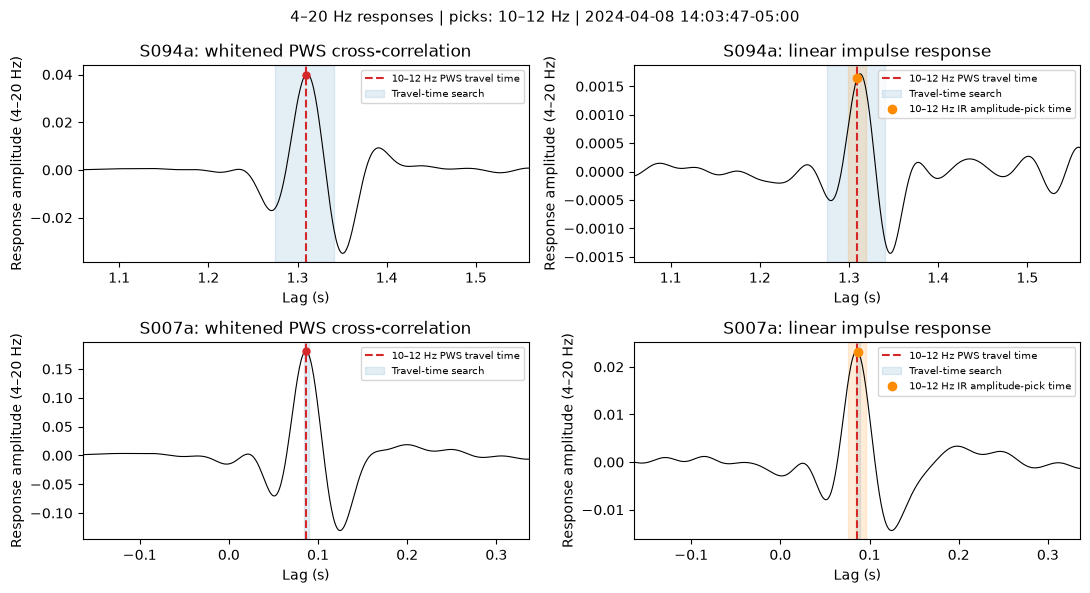

In [8]:
PLOT_FL, PLOT_FH = 4.0, 20.0
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, station in enumerate((RECEIVER, REFERENCE)):
    broadband = prepared[station].copy().filter(
        'bandpass', freqmin=PLOT_FL, freqmax=PLOT_FH, corners=4, zerophase=True)
    narrowband = prepared[station].copy().filter(
        'bandpass', freqmin=FL, freqmax=FH, corners=4, zerophase=True)
    pick = picks[station]
    narrow_ir = narrowband.select(channel='IR')[0]
    narrow_lag = narrow_ir.times(reftime=t0)
    idx = int(round((pick['trav_time']-narrow_lag[0])*narrow_ir.stats.sampling_rate))
    first, last = max(idx-10,0), min(idx+11,len(narrow_lag))
    amplitude_index = first + int(np.argmax(narrow_ir.data[first:last]))
    amplitude_time = narrow_lag[amplitude_index]
    np.testing.assert_allclose(narrow_ir.data[amplitude_index], pick['amplitude'])
    for col, channel in enumerate(('WXCR','IR')):
        tr = broadband.select(channel=channel)[0]
        lag = tr.times(reftime=t0)
        ax = axes[row,col]
        ax.plot(lag,tr.data,color='black',lw=0.8)
        ax.axvline(pick['trav_time'],color='tab:red',ls='--',label='10–12 Hz PWS travel time')
        ax.axvspan(pick['t_min'],pick['t_max'],alpha=0.12,color='tab:blue',label='Travel-time search')
        if channel == 'WXCR':
            ax.plot(pick['trav_time'],np.interp(pick['trav_time'],lag,tr.data),
                    'o',color='tab:red',ms=5)
        else:
            ax.plot(amplitude_time,np.interp(amplitude_time,lag,tr.data),
                    'o',color='darkorange',label='10–12 Hz IR amplitude-pick time')
            ax.axvspan(pick['trav_time']-0.010,pick['trav_time']+0.010,color='darkorange',alpha=0.15)
        ax.set_xlim(pick['trav_time']-0.25,pick['trav_time']+0.25)
        ax.set_title(f'{station}: '+('whitened PWS cross-correlation' if channel=='WXCR' else 'linear impulse response'))
        ax.set_xlabel('Lag (s)')
        ax.set_ylabel('Response amplitude (4–20 Hz)')
        ax.legend(fontsize=7)
fig.suptitle('4–20 Hz responses | picks: 10–12 Hz | '+str(local_time(event_time)),fontsize=11)
fig.tight_layout()
plt.show()